In [1]:
import matplotlib.pylab as plt 
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge

# 1. Cost functions

Lets focus on linear regression of the form 

$\mathbf{y} \approx f(\mathbf{X}) = \mathbf{X}\mathbf{w_1} + \mathbf{w_0}.$


#### 1.1 What are the rows of $\mathbf{X}$?

The rows of $\mathbf{X}$ are the observations. Each row represents a single observation.

#### 1.2 What are the columns of $\mathbf{X}$?

The column of $\mathbf{X}$ are the features/variables. Each column represents a feature/variable.

Often, we write the equation above as

$\mathbf{y} \approx \mathbf{\tilde{X}}\mathbf{w}$

#### 1.3 How does $\mathbf{\tilde{X}}$ look like in this case (i.e., how does the shape of the matrix change compared to $\mathbf{X}$)?

$\tilde{\mathbf{X}}$ is $\mathbf{X}$ with an extra column of ones, which accounts for the intercept $\omega_0$. If $\mathbf{X}$ has shape $n \times p$, then $\tilde{\mathbf{X}}$ has shape $n \times (p + 1)$. The column of 1 ensure that the same intercept $\omega _{0}$ is added to every prediction.

For machine learning, we need a cost function. Two common choices are the mean-squared error (MSE, $\mathcal{L}_2$), and the mean-absolute error (MAE, $\mathcal{L}_1$)

\begin{align}
    \mathcal{L}_2 &=& \frac{1}{N} \sum_{i=1}^N \left(y_i - f(x_i) \right)^2 \\
    \mathcal{L}_1 &=& \frac{1}{N} \sum_{i=1}^N \left|y_i - f(x_i) \right| 
\end{align}

#### 1.4 In the Jupyter notebook, write a Python function that computes these two cost functions given an error term $\boldsymbol{\epsilon} = \mathbf{y} - \mathbf{\tilde{X}}\mathbf{w}$

In [6]:
def mean_squared_error(error_vector):
    mean_squared_error = np.mean(error_vector**2)
    return mean_squared_error

In [7]:
def mean_absolute_error(error_vector):
    mean_absolute_error = np.mean(np.abs(error_vector))
    return mean_absolute_error

Test of the two functions:

In [8]:
print(mean_squared_error(np.array([0,0,0])))

print(mean_squared_error(np.array([-2, 0, 4])))

print(mean_absolute_error(np.array([0,0,0])))

print(mean_absolute_error(np.array([-2, 0, 4])))

0.0
6.666666666666667
0.0
2.0


Your code should run as follows

```python
mean_squared_error(np.array([0,0,0]))
> returns 0
```

```python
mean_squared_error(np.array([1,1,1]))
> returns 1
```

#### 1.5 What is the shape of these cost functions as a function of the error

In [9]:
x_axis = np.linspace(-3,3,301) 
y_mae = [mean_absolute_error(x) for x in x_axis]
y_mse = [mean_squared_error(x) for x in x_axis]

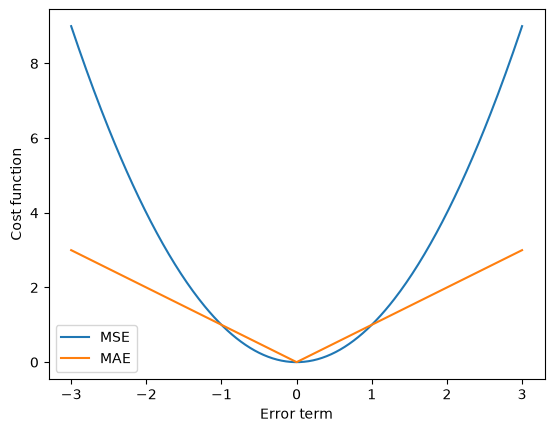

In [10]:
plt.plot(x_axis, y_mse, label='MSE')
plt.plot(x_axis, y_mae, label='MAE')
plt.xlabel('Error term')
plt.ylabel('Cost function')
plt.legend()
plt.show()

In one dimension, MSE is $\epsilon^2$, an upward-opening parabola, while MAE is $|\epsilon|$, a V-shaped function. Both are symmetric around zero and have their minimum at zero. MSE grows quadratically, so it penalizes large errors more strongly than MAE, which grows linearly.

#### 1.6  Are both loss functions differentiable for all $\boldsymbol{\epsilon}$? What implications does this have for gradient based optimization like gradient descent?

We can zoom in around 0 to see the difference between the two functions:

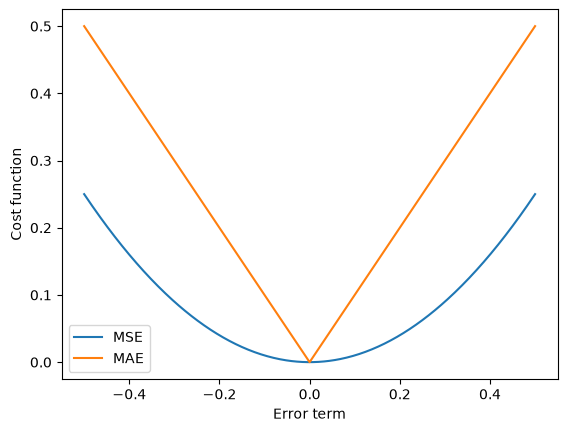

In [11]:
x_axis = np.linspace(-0.5, 0.5, 501) 
y_mae = [mean_absolute_error(x) for x in x_axis]
y_mse = [mean_squared_error(x) for x in x_axis]

plt.plot(x_axis, y_mse, label='MSE')
plt.plot(x_axis, y_mae, label='MAE')
plt.xlabel('Error term')
plt.ylabel('Cost function')
plt.legend()
plt.show()

Near $\epsilon$ = 0:
- MSE has a smooth bottom, with slope 0.
- MAE has a sharp corner: the slope is -1 on the left and +1 on the right.

Mathematically, MSE is differentiable for every error $\epsilon$, including 0:
$$
L(\epsilon)=\epsilon^2, \quad L'(\epsilon) = 2\epsilon
$$

MAE is differentiable everywhere except at $\epsilon$ = 0, where its V-shape has a sharp corner:
$$
L(\epsilon)=|\epsilon|, \quad L'(\epsilon) = \begin{cases} -1 & \text{if } \epsilon < 0, \\
1 & \text{if } \epsilon > 0.
\end{cases}
$$

For gradient descent, MSE provides a gradient everywhere, which approaches zero as the error approaches zero. MAE requires a subgradient at zero, commonly chosen as 0.

#### 1.7 Which loss function is more sensitive to outliers and why?

The difference in sensitivity of the two loss functions can be shown graphically

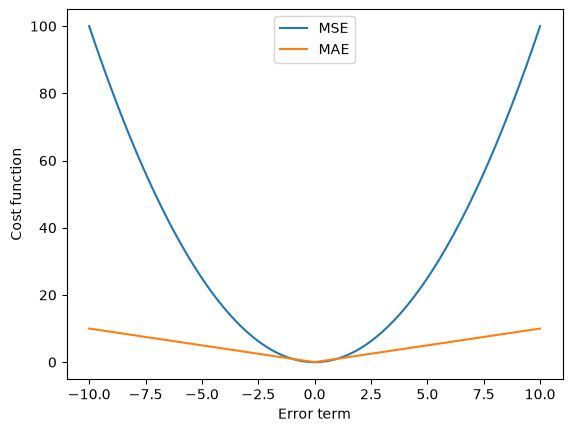

In [12]:

x_axis = np.linspace(-10, 10, 501) 
y_mae = [mean_absolute_error(x) for x in x_axis]
y_mse = [mean_squared_error(x) for x in x_axis]

plt.plot(x_axis, y_mse, label='MSE')
plt.plot(x_axis, y_mae, label='MAE')
plt.xlabel('Error term')
plt.ylabel('Cost function')
plt.legend()
plt.show()

MSE is more sensitive to outliers than MAE. In fact, MSE squares each error ($\epsilon^2$) while MAE uses its absolute value (|$\epsilon$|). For large errors, the squared values grow much faster.

As an example shown on the graph above, an error of 10 contributes to 100 to squared loss but only 10 to absolute loss.

# 2. Regularization

Assume that the columns of $\mathbf{X}$ are linearly independent.
As a refresher of linear algebra, recall when the linear system $\mathbf{X}\mathbf{w} = \mathbf{y}$ has

#### 2.1 One unique solution

The system $Xw = y$ has a unique solution when:

- $\operatorname{rank}(X) = \operatorname{rank}([X \mid y]) = D$, where $D$ is the number of unknowns (columns of $X$).

This occurs when $X$ has full column rank and $y$ lies in the column space of $X$. Full column rank requires $N \geq D$ and linearly independent columns.

#### 2.2 No solution

The system $Xw = y$ has no solution when:

- $\operatorname{rank}(X) < \operatorname{rank}([X \mid y])$.

This means that $y$ does not lie in the column space of $X$.

Since the columns of $X$ are linearly independent, this can only occur when $N > D$.

#### 2.3 An infinite number of solutions

In general, the system $Xw = y$ has infinitely many solutions when:

- $\operatorname{rank}(X) = \operatorname{rank}([X \mid y]) < D$.

The system is consistent and has at least one free variable.

However, under the assumption that the columns of $X$ are linearly independent, $\operatorname{rank}(X) = D$, so infinitely many solutions are impossible.

#### 2.4 Give a geometrical interpretation of the matrix Rank (10 bonus point if you use the Manim package)

The rank of a matrix $X$ is the dimension of its column space, which is the set of all possible outputs $Xw$.

Geometrically:
- Rank 0: the image is the origin.
- Rank 1: the image is a line through the origin.
- Rank 2: the image is a plane through the origin.
- Rank 3: the image is a three-dimensional subspace.

More generally, rank $r$ means that the image is an $r$-dimensional subspace.

Since the columns of $X$ are assumed to be linearly independent, its rank equals the number of columns $D$. The transformation therefore maps distinct input vectors to distinct output vectors, without collapsing any input direction.

The rank tells us how many linearly independent directions the matrix captures. See the animation [Rank2D.mp4](Rank2D.mp4), generated using Manim.

#### 2.5 In general, why can't we solve the linear equation using $\mathbf{y} = \tilde{\mathbf{X}}^{-1}\textbf{w}$? (1 point)

We cannot use this formula because:

1. $\tilde{X}$ is typically not square: it has $N$ rows (samples) and $D+1$ columns (features including the intercept), so it has no ordinary inverse.
2. In general, without the independence assumption, even a square $\tilde{X}$ can be singular (not invertible) if its columns are linearly dependent.

#### 2.6 Differentiate above formula step by step and show what will we have?

Assuming the formula to differentiate is the squared-error objective:

$$
L(w) = \|y-\tilde{X}w\|_2^2
     = (y-\tilde{X}w)^T(y-\tilde{X}w).
$$

Expanding:
$$
L(w) = y^Ty-y^T\tilde{X}w-w^T\tilde{X}^Ty
       +w^T\tilde{X}^T\tilde{X}w.
$$

Since $y^T\tilde{X}w = w^T\tilde{X}^Ty$:
$$
L(w) = y^Ty-2w^T\tilde{X}^Ty
       +w^T\tilde{X}^T\tilde{X}w.
$$

Differentiating with respect to $w$, using the symmetry of $\tilde{X}^T\tilde{X}$:
$$
\boxed{\nabla_w L(w)=-2\tilde{X}^Ty+2\tilde{X}^T\tilde{X}w.}
$$

#### 2.7 if we want $\| y - \tilde{X} w \|_2^2$ to be minimum, what should the derivative be equal to?

Since we are searching an optimum, the derivative should be: $$\frac{\partial L(w)}{\partial w}=0.$$
The optimum given will be the minimum seached as the second derivative does not contan a negative, indicating that $L(w)$ is convex. $$\frac{\partial ^2 L(w)}{\partial w^2}=2\tilde{X}^T\tilde{X}\geq 0.$$

#### 2.8 What is the Hat matrix and what does its diagonal values correspond to?

The hat matrix, also known as the projection matrix, projects the vector of observations $y$ onto the vector of predictions $\hat{y}$. It is written as:$$\boxed{H = X(X^TX)^{-1}X^T}.$$

The diagonal elements $h_{ii}$ are called leverage values. They measure how unusual an observation’s input values are relative to the dataset and indicate its potential influence on the regression model, hence their values vary between 0 and 1.

#### 2.9 What is William’s plot and how does it help in outlier detection?

A William's plot is a regression diagnostic tool. It plots the leverage values  of the Hat Matrix, on the horizontal axis and the standardized residuals on the vertical axis.

The leverage values indicate how unusual an observation is in the predictor space, while the standardized residuals measure how much the observed values differ from the predicted values.

By combining these two measures, the Williams plot helps identify observations with unusually high leverage or large prediction errors, which may influence the regression model.

#### 2.10 What happens if some columns are linearly dependent? What is the connection to feature selection?

If some columns are linearly dependent, then there is at least one free variable. 
Therefore the rank of $X$ can be written as:
- $\operatorname{rank}(X) = \operatorname{rank}([X \mid y]) < D$, which is the case when there is an infinite amount of solutions
- $\operatorname{rank}(X) < \operatorname{rank}([X \mid y])$, which is the case when there is no solution.

Linearly dependent columns indicate redundant features aswell. Feature selection can remove these, reducing the dimensions of the model and help avoid problems caused by linear dependence.

#### 2.11 What will be the new cost function after adding the regularization term?

The new cost function will be:$$ J_{\text{reg}}(w) = \|y-\tilde{X}w\|_2^2 + \lambda\|w\|_2^2. $$

#### 2.12 What will be the new 𝑤 when we differentiate the new cost function and set it to zero.

The derivative of the new cost function with respect to $w$ is:

$$ \frac{\partial J_{\text{reg}}(w)}{\partial w} = -2\tilde{X}^T(y-\tilde{X}w)+2\lambda w. $$

When we differentiate and set it to zero, we obtain:

$$ -2\tilde{X}^T(y-\tilde{X}w)+2\lambda w=0. $$

This equation can be rearranged to write:

$$ (\tilde{X}^T\tilde{X}+\lambda I)w=\tilde{X}^Ty. $$

Therefore the new $w$ are:

$$ w=(\tilde{X}^T\tilde{X}+\lambda I)^{-1}\tilde{X}^Ty. $$

#### 2.13 Prove that the part of Hat matrix where we want to take the inverse from is always reversible after we introduce the regularization term.

The matrix to invert is $\tilde{X}^T\tilde{X}+\lambda I$, where $\lambda>0$ is the regularization parameter.

The matrix $\tilde{X}^T\tilde{X}$ is positive semidefinite because, for any non-zero vector $v$,

$$
v^T\tilde{X}^T\tilde{X}v
= \|\tilde{X}v\|_2^2 \geq 0.
$$

Adding the regularization term gives

$$
v^T(\tilde{X}^T\tilde{X}+\lambda I)v
= \|\tilde{X}v\|_2^2+\lambda\|v\|_2^2 > 0.
$$

Therefore, $\tilde{X}^T\tilde{X}+\lambda I$ is positive definite and hence invertible.

Regularization thus guarantees invertibility when $\lambda>0$, even if $\tilde{X}^T\tilde{X}$ is singular.



#### 2.14  What is the shape of the parabola as a function of $a$?

In [3]:
def parabola(x, a = 1): 
    return a * x ** 2

In [4]:
x_axis_parabola = np.linspace(-10, 10, 100)

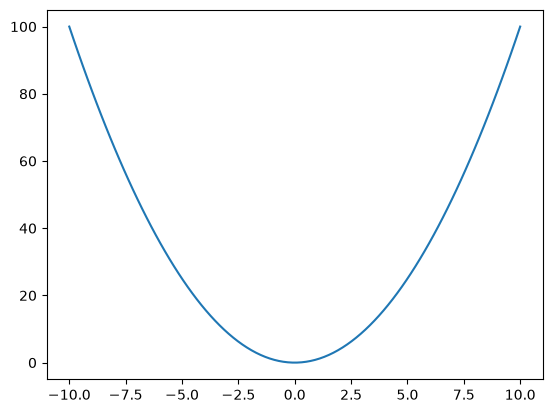

In [5]:
plt.plot(x_axis_parabola, parabola(x_axis_parabola))

The function is

$$
f(x)=ax^2.
$$

The parameter $a$ determines the shape of the parabola.

- If $a>0$, the parabola opens upward.
- If $a<0$, the parabola opens downward.
- If $a=0$, the function is a horizontal line at $y=0$.

The larger the absolute value $|a|$, the narrower the parabola. The smaller the absolute value $|a|$, the wider the parabola.

The vertex is always at $(0,0)$.

#### 2.15 Plot the approximation to the function for different order polynomials ($N \in \{1, 2, 16\}$) and with different regularization strength ($\lambda \in \{0, 10^{-3}, 10^{-2}, 1\}$). What do you observe 

In [3]:
def true_function(X):
    return np.cos(1.5 * np.pi * X)

In [4]:
X_test = np.linspace(0, 1, 100) # some grid for us on the x axis

In [5]:
n_samples = 10 # the number of points we will sample from true_function
degrees = [1, 2, 16] # the polynomial degrees we will test

X = np.sort(np.random.rand(n_samples))
y = true_function(X) + np.random.randn(n_samples) * 0.1 # add some scaled random noise

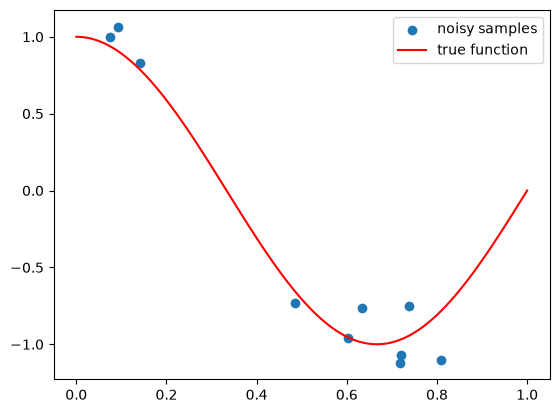

In [6]:
plt.scatter(X, y, label='noisy samples')
plt.plot(X_test, true_function(X_test), c='r', label='true function')
plt.legend()

The following code will fit a polynomial regression, you need to fill the degree

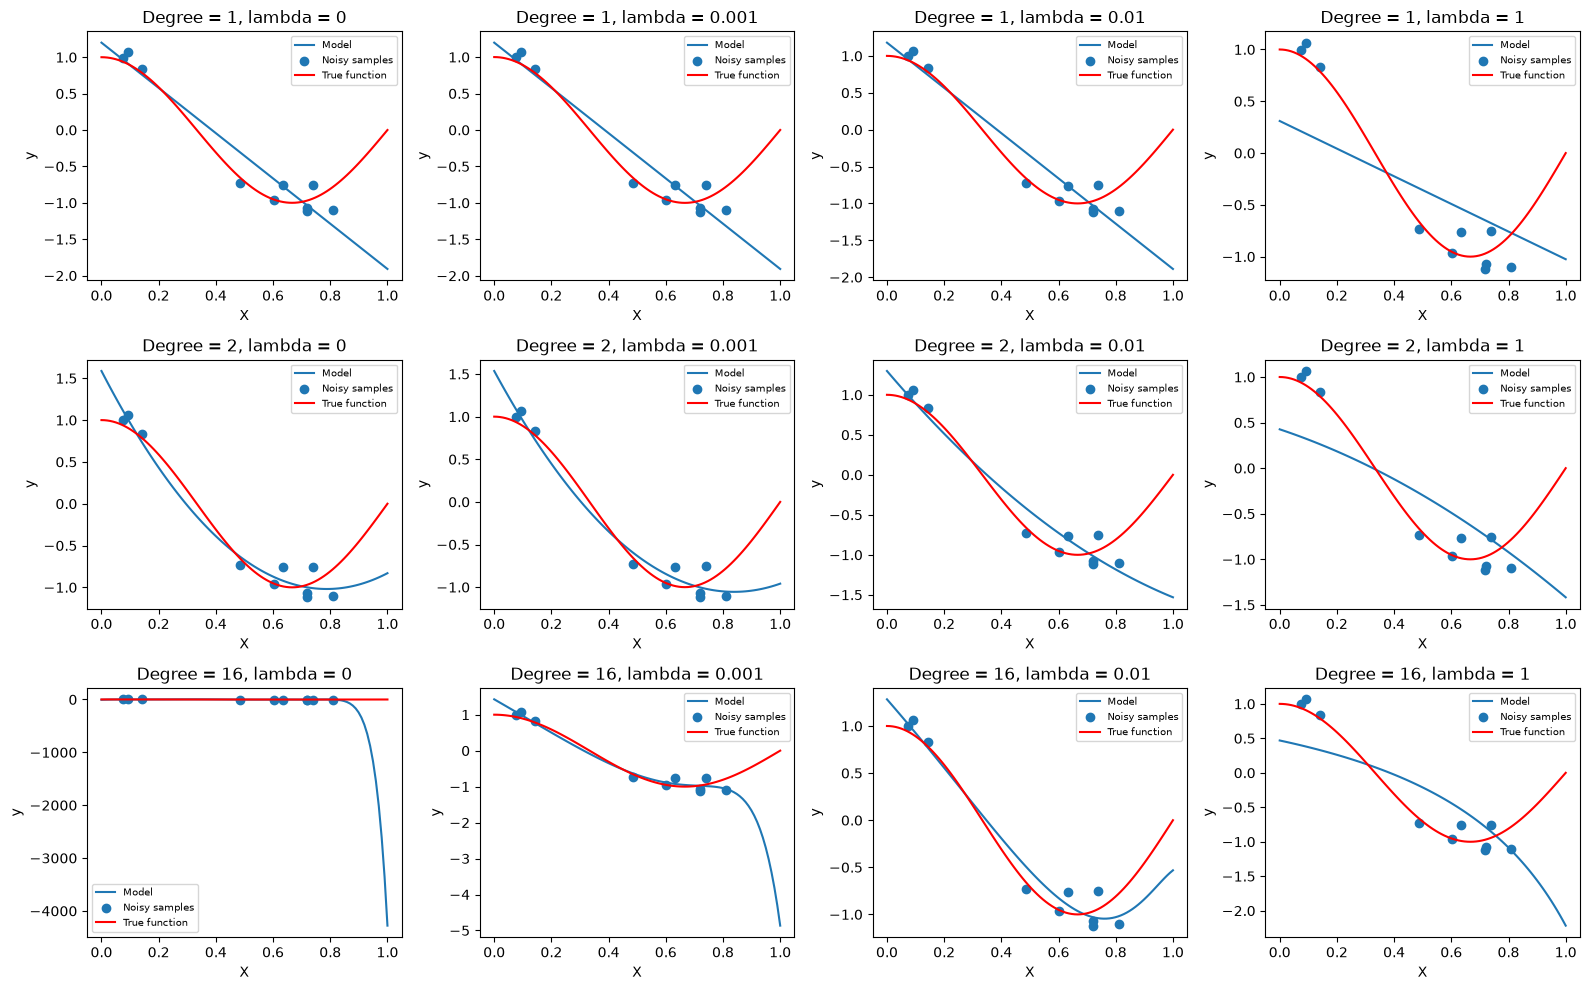

In [12]:
degrees = [1, 2, 16]
lambdas = [0, 0.001, 0.01, 1]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for i, degree in enumerate(degrees):
    for j, lam in enumerate(lambdas):

        polynomial_features = PolynomialFeatures(
            degree=degree,
            include_bias=False
        )

        if lam == 0:
            regression = LinearRegression()
        else:
            regression = Ridge(alpha=lam)

        model = Pipeline([
            ("polynomial_features", polynomial_features),
            ("regression", regression)
        ])

        model.fit(X[:, np.newaxis], y)

        ax = axes[i, j]

        ax.plot(
            X_test,
            model.predict(X_test[:, np.newaxis]),
            label="Model"
        )
        ax.scatter(X, y, label="Noisy samples")
        ax.plot(
            X_test,
            true_function(X_test),
            c="red",
            label="True function"
        )

        ax.set_title(f"Degree = {degree}, lambda = {lam}")
        ax.set_xlabel("X")
        ax.set_ylabel("y")
        ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

### Observations

The structure of the wanted code was modified for efficiency purposes as many graphs were required 

A polynomial of degree 1 is too simple to capture the shape of the true function, which leads to underfitting. 

A polynomial of degree 16 is much more flexible and can fit the training samples closely. However, without regularization, it may overfit the noise and oscillate strongly between the samples.

Increasing the regularization strength $\lambda$ penalizes large coefficients and generally makes the fitted curve smoother. If the regularization is too strong, the model may become too simple and underfit the data.

Therefore, both the polynomial degree and the regularization strength influence the model's ability to approximate the true function.

#### 2.16 What do you observe if you change the number of samples from the function?

With very few samples, the fitted model is more sensitive to noise and may not represent the underlying function well. Increasing the number of samples generally gives the model more information about the function and makes the approximation more reliable. However, the result also depends on the polynomial degree and the regularization strength.

#### 2.17 Why do we need a test set in machine learning?

A test set estimates how well the trained model generalizes to unseen data. Since the model is fitted using the training set, its performance on that same data can be overly optimistic. Evaluating on a separate test set gives a more independent assessment of predictive performance.

#### 2.18 If we need to optimize hyperparameters, do we use the test set to select the best hyperparameters? (1 point)

No. Hyperparameters should be selected using a validation set or cross-validation on the training data. The test set should be kept separate and used only for the final evaluation; using it repeatedly to choose hyperparameters leaks information and gives an optimistically biased estimate of generalization.